#  **Wildfire Dynamics Prediction Project**

In [1]:
# Import all required libraries for this project
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import random

**Step 1: Load and Preprocess Data**

In [3]:
# Load the wildfire detection dataset (MODIS-based)
df = pd.read_csv("modis_2023_United_States.csv")

# Convert the acquisition date column to datetime type
df['acq_date'] = pd.to_datetime(df['acq_date'])

# Filter for California region based on latitude and longitude bounds
lat_min, lat_max = 32.0, 42.0
lon_min, lon_max = -125.0, -114.0
df_ca = df[(df['latitude'] >= lat_min) & (df['latitude'] <= lat_max) &
           (df['longitude'] >= lon_min) & (df['longitude'] <= lon_max)]

In [4]:
# Set up 2D grid dimensions (100x100) for spatial resolution
grid_size = (100, 100)
lat_bins = np.linspace(lat_min, lat_max, grid_size[0]+1)
lon_bins = np.linspace(lon_min, lon_max, grid_size[1]+1)

In [7]:
# Group fire detections by date and create a brightness heatmap for each day (We will use this for Visualization)
df_grouped = df_ca.groupby('acq_date')
date_to_grid = {}

for date, group in df_grouped:
    # Convert geospatial fire data into a 2D histogram (heatmap)
    hist, _, _ = np.histogram2d(
        group['latitude'], group['longitude'],
        bins=[lat_bins, lon_bins],
        weights=group['brightness']  # Use brightness as intensity
    )
    # Normalize brightness map between 0 and 1 for training stability
    norm_hist = (hist - np.min(hist)) / (np.max(hist) - np.min(hist)) if np.max(hist) != np.min(hist) else hist
    date_to_grid[date] = norm_hist

In [8]:
# Sort the grids by date and filter out empty (non-fire) days
sorted_dates = sorted(date_to_grid.keys())
grids = [date_to_grid[date] for date in sorted_dates if date_to_grid[date].sum() > 0]

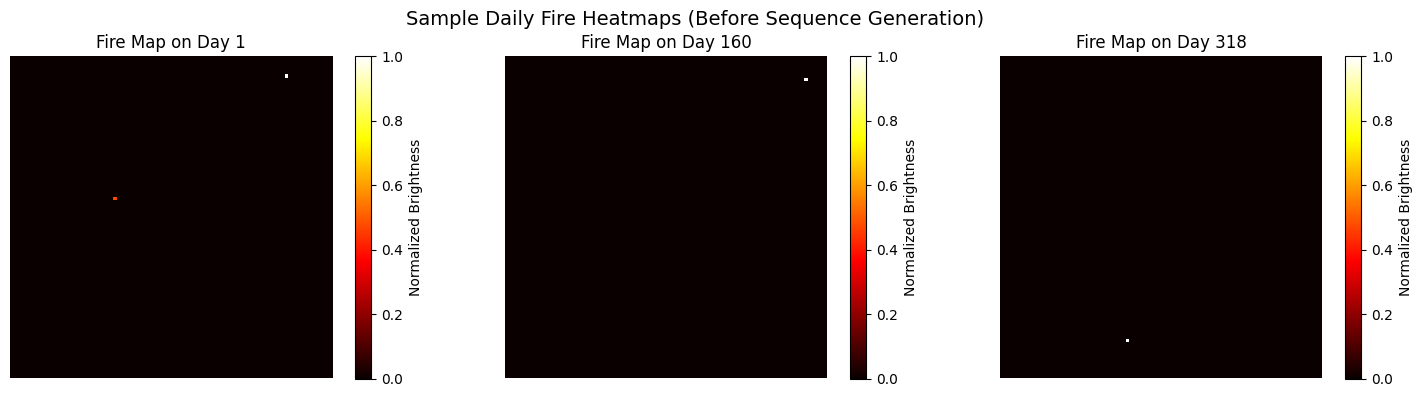

In [16]:
# Visualize sample fire maps from the preprocessed daily grids
sample_days = [0, len(grids)//2, len(grids)-1]  # first, middle, last day

plt.figure(figsize=(15, 4))

for i, day_idx in enumerate(sample_days):
    plt.subplot(1, 3, i+1)
    plt.imshow(grids[day_idx], cmap='hot', interpolation='nearest')
    plt.title(f"Fire Map on Day {day_idx+1}")
    plt.colorbar(label='Normalized Brightness')
    plt.axis('off')

plt.suptitle("Sample Daily Fire Heatmaps (Before Sequence Generation)", fontsize=14)
plt.tight_layout()
plt.show()


# What This Shows
A quick visual check to ensure the fire grid construction is working. ( for example We have visualization for 3 random days)

Confirms that fire locations and intensities are meaningfully encoded.

Helps you explain to evaluators or teammates how raw satellite brightness becomes usable ML input.

**Step 2: Prepare Sequences for ML Model**

In [9]:
# Each input sequence will be 7 days long, and the model will predict the 8th day
sequence_length = 7
X, y = [], []

for i in range(len(grids) - sequence_length):
    X.append(grids[i:i+sequence_length])        # Sequence of 7 days
    y.append(grids[i+sequence_length])          # Target: fire map on day 8

# Convert sequences to numpy arrays
X = np.array(X)  # Shape: (samples, 7, 100, 100)
y = np.array(y)  # Shape: (samples, 100, 100)

# Split into training and testing datasets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Step 3: Define CNN-LSTM Model**

In [11]:
def build_model(input_shape):
    # Define a CNN-LSTM hybrid model for spatio-temporal prediction
    model = models.Sequential([
        layers.TimeDistributed(layers.Conv2D(32, (3, 3), activation='relu', padding='same'), input_shape=input_shape),
        layers.TimeDistributed(layers.MaxPooling2D((2, 2))),  # Downsample
        layers.TimeDistributed(layers.Conv2D(64, (3, 3), activation='relu', padding='same')),
        layers.TimeDistributed(layers.MaxPooling2D((2, 2))),  # Further downsample
        layers.TimeDistributed(layers.Flatten()),             # Flatten for LSTM
        layers.LSTM(64),                                      # Capture temporal features
        layers.Dense(100*100, activation='sigmoid'),          # Predict fire map (flattened)
        layers.Reshape((100, 100))                            # Reshape to original grid
    ])

    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# Reshape X_train to add a channel dimension
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], X_train.shape[2], X_train.shape[3], 1)

# Build model using shape: (timesteps=7, height=100, width=100, channels=1)
model = build_model(X_train.shape[1:])
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/wrapper.py:27: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_5              │ (None, 7, 100, 100,    │           320 │
│ (TimeDistributed)               │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, 7, 50, 50, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, 7, 50, 50, 64)  │        18,496 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_8              │ (None, 7, 25, 25, 64)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_9              │ (None, 7, 40000)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │    10,256,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10000)          │       650,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 100, 100)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,925,456 (41.68 MB)

 Trainable params: 10,925,456 (41.68 MB)

 Non-trainable params: 0 (0.00 B)

**Step 4: Train the Model**

In [31]:
# Train for 10 epochs with a small batch size
history = model.fit(X_train, y_train, epochs=5, batch_size=3, validation_split=0.3)

Epoch 1/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - loss: 9.3258e-04 - mae: 0.0270 - val_loss: 8.0310e-04 - val_mae: 0.0244
Epoch 2/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - loss: 7.7508e-04 - mae: 0.0237 - val_loss: 6.8354e-04 - val_mae: 0.0217
Epoch 3/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - loss: 6.6408e-04 - mae: 0.0212 - val_loss: 6.0025e-04 - val_mae: 0.0196
Epoch 4/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - loss: 6.2058e-04 - mae: 0.0193 - val_loss: 5.3928e-04 - val_mae: 0.0180
Epoch 5/5
58/58 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - loss: 5.1399e-04 - mae: 0.0176 - val_loss: 4.9339e-04 - val_mae: 0.0166


**Step 5: Evaluate and Visualize**

In [32]:
# Reshape X_test to match the input shape expected by the model (add channel dimension)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], X_test.shape[2], X_test.shape[3], 1)

# Evaluate model on test set
loss, mae = model.evaluate(X_test, y_test)
print("Test MSE:", loss)
print("Test MAE:", mae)

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - loss: 4.8490e-04 - mae: 0.0166
Test MSE: 0.00048067994066514075
Test MAE: 0.01656043902039528


In [33]:
# Predict on a random test sample and compare with actual output
index = random.randint(0, len(X_test)-1)
predicted = model.predict(X_test[index:index+1])[0]
actual = y_test[index]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


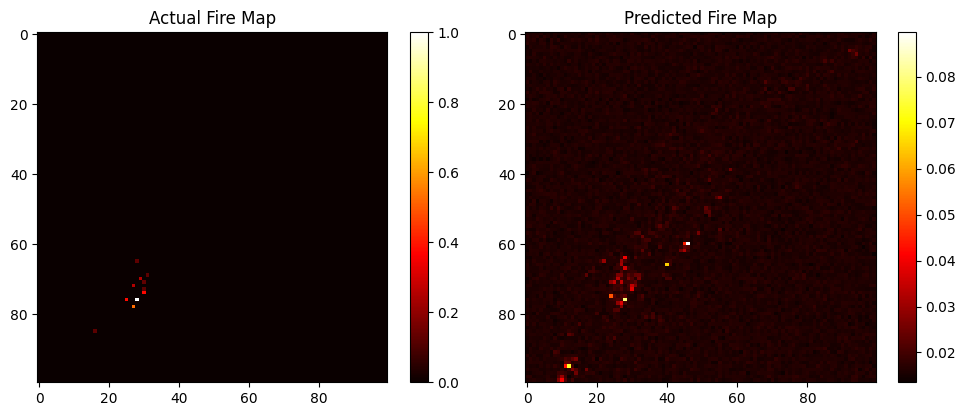

In [34]:
# Plot side-by-side heatmaps: actual vs predicted fire spread
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(actual, cmap='hot')
plt.title("Actual Fire Map")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(predicted, cmap='hot')
plt.title("Predicted Fire Map")
plt.colorbar()

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


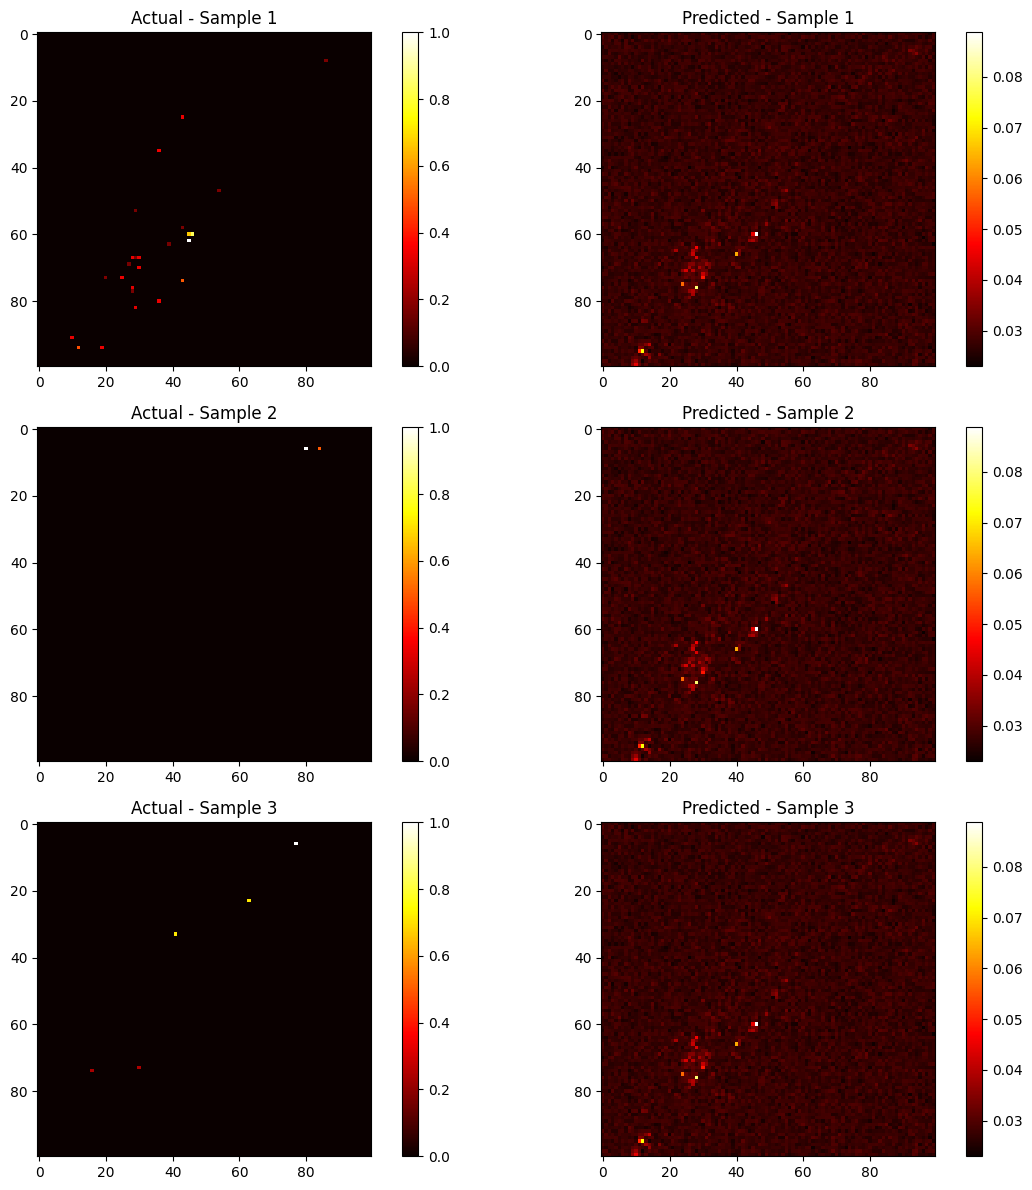

In [21]:
n_samples = 3  # You can change to show more/less
plt.figure(figsize=(12, n_samples * 4))

for i in range(n_samples):
    idx = random.randint(0, len(X_test) - 1)
    pred = model.predict(X_test[idx:idx+1])[0]
    true = y_test[idx]

    plt.subplot(n_samples, 2, 2*i + 1)
    plt.imshow(true, cmap='hot')
    plt.title(f"Actual - Sample {i+1}")
    plt.colorbar()

    plt.subplot(n_samples, 2, 2*i + 2)
    plt.imshow(pred, cmap='hot')
    plt.title(f"Predicted - Sample {i+1}")
    plt.colorbar()

plt.tight_layout()
plt.show()


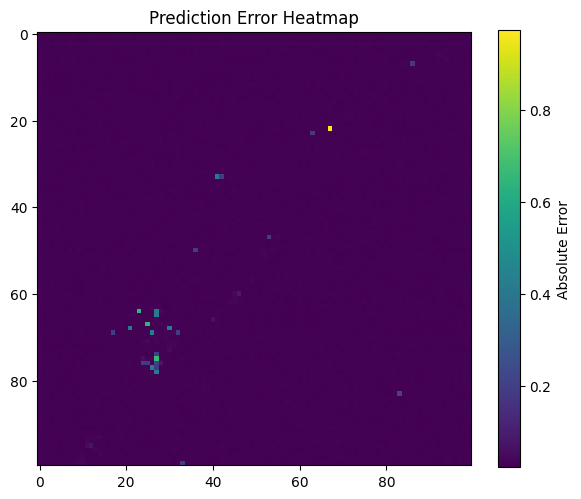

In [22]:
error_map = np.abs(predicted - actual)

plt.figure(figsize=(6, 5))
plt.imshow(error_map, cmap='viridis')
plt.title('Prediction Error Heatmap')
plt.colorbar(label='Absolute Error')
plt.tight_layout()
plt.show()


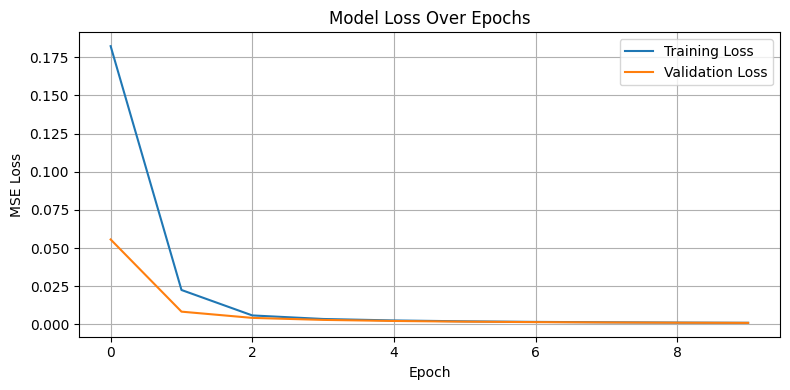

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━

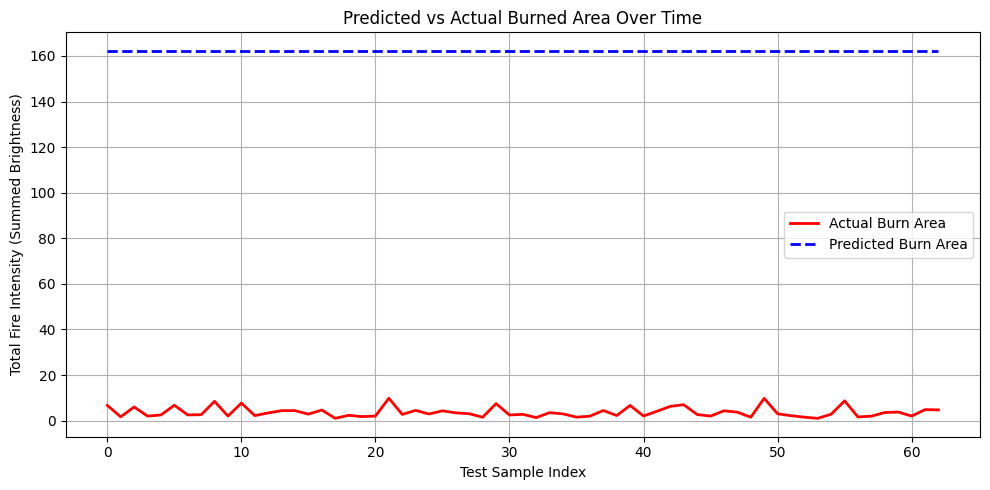

In [35]:
actual_area = [np.sum(y_test[i]) for i in range(len(y_test))]
predicted_area = [np.sum(model.predict(X_test[i:i+1])[0]) for i in range(len(X_test))]

plt.figure(figsize=(10, 5))
plt.plot(actual_area, label='Actual Burn Area', color='red', linewidth=2)
plt.plot(predicted_area, label='Predicted Burn Area', color='blue', linestyle='--', linewidth=2)
plt.title('Predicted vs Actual Burned Area Over Time')
plt.xlabel('Test Sample Index')
plt.ylabel('Total Fire Intensity (Summed Brightness)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step


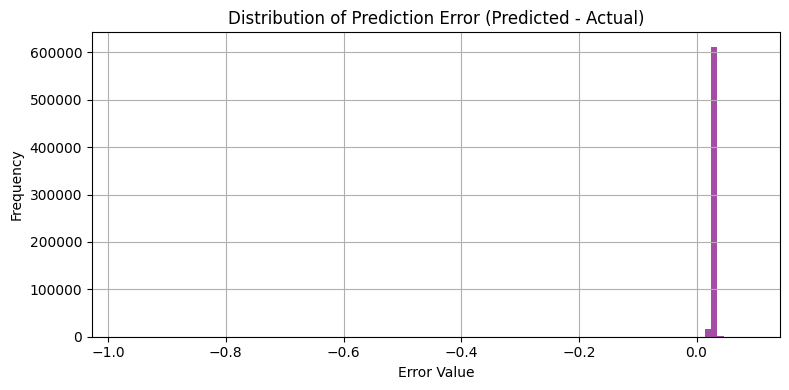

In [30]:
# Get predictions for all test data
y_pred_all = model.predict(X_test)

# Calculate errors
errors = (y_pred_all - y_test).flatten()

plt.figure(figsize=(8, 4))
plt.hist(errors, bins=100, color='purple', alpha=0.7)
plt.title("Distribution of Prediction Error (Predicted - Actual)")
plt.xlabel("Error Value")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()